# Medium world — Mastery-based progression

Compare three schedules: **fixed-late**, **fixed-early**, and **mastery-triggered** progression. All three retain quota-based rehearsal during later stages and use the same 9,000-update budget with constant LR.

Primary outcome: **final held-out ID-dev binding accuracy**. Secondary outcomes: OOD binding, retention, learning curves, and transition timing. This remains exploratory: the fixed-early boundaries came from the previous seed-42 pilot, and mastery thresholds were informed by development-set observations.
This notebook can record per-question predictions and correctness for the entire ID-dev and OOD-dev sets at each evaluation checkpoint. Historical summaries cannot retroactively provide these predictions.


In [ ]:
from pathlib import Path
SEEDS = [42, 43, 44, 45, 46]
POLICIES = ("fixed_late", "fixed_early", "mastery")
MAIN_EPOCHS, COMMON_EPOCHS = 36, 9
BATCH_SIZE, EVAL_EVERY = 50, 100
LR, WEIGHT_DECAY = 1e-4, 0.0
MODEL_DIM, PATCH_SIZE = 48, 4
AUGMENT, DEVICE = True, "cuda"
FIXED_STEPS = {"fixed_late": (3000, 5000), "fixed_early": (1400, 2200)}
MIN_ATTR_STEPS, MAX_ATTR_STEP = 1200, 3000
MIN_CONJ_STEPS, MAX_CONJ_STEP = 800, 5400
ATTR_TARGETS = {"color": .94, "shape": .70}
CONJ_TARGETS = {"conjunction": .77, "color": .91, "shape": .68}
SMOOTH_EVALS, REQUIRED_CHECKS = 3, 2
DATA_REL = Path("outputs/medium_world/dataset")
OUT_REL = Path("outputs/medium_world/experiments/mastery_progression")
# Keep existing completed experiment results unchanged.
RUN_NEW_EXPERIMENTS = True
SAVE_PREDICTION_TRACES = True

In [2]:
import sys, json, random, hashlib, time
from collections import Counter, deque
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from IPython.display import display

PROJECT_ROOT = Path().cwd().parent.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from src.medium_visual_world.learning import (
    TASKS, MediumDataset, AttributeBindingViT, augment_images, set_seed, environment
)
from src.medium_visual_world.curriculum import repeated
from src.medium_visual_world.prediction_tracking import (
    PredictionTrace, evaluate_predictions
)

device = torch.device(DEVICE)
DATA_DIR, OUT_DIR = PROJECT_ROOT / DATA_REL, PROJECT_ROOT / OUT_REL
train = MediumDataset(DATA_DIR / "train.jsonl")
dev = MediumDataset(DATA_DIR / "id_dev.jsonl")
ood = MediumDataset(DATA_DIR / "ood_dev.jsonl")
hashes = {name: hashlib.sha256((DATA_DIR / name).read_bytes()).hexdigest()
          for name in ("train.jsonl", "id_dev.jsonl", "ood_dev.jsonl")}
MAIN_STEPS = len(train) * MAIN_EPOCHS // BATCH_SIZE
TOTAL_STEPS = len(train) * (MAIN_EPOCHS + COMMON_EPOCHS) // BATCH_SIZE

# Keep both questions from the same scene in the same ID-dev partition.
scenes = sorted({row["scene_id"] for row in dev.rows},
                key=lambda scene: hashlib.sha256(f"mastery-v1:{scene}".encode()).hexdigest())
progress_scenes = set(scenes[:len(scenes) // 2])
progress_ids = [i for i, row in enumerate(dev.rows) if row["scene_id"] in progress_scenes]
heldout_ids = [i for i, row in enumerate(dev.rows) if row["scene_id"] not in progress_scenes]
print(f"{device} | {MAIN_STEPS} main + {TOTAL_STEPS-MAIN_STEPS} common steps | "
      f"progress={len(progress_ids)} heldout={len(heldout_ids)} ID-dev examples")

cuda | 7200 main + 1800 common steps | progress=512 heldout=512 ID-dev examples


In [3]:
@torch.inference_mode()
def evaluate_subset(model, dataset, indices):
    model.eval()
    correct, total_loss = 0, 0.0
    counts, hits = Counter(), Counter()
    for start in range(0, len(indices), BATCH_SIZE):
        ids = indices[start:start + BATCH_SIZE]
        x, q, y = dataset.batch(ids, device)
        logits = model(x, q)
        total_loss += nn.functional.cross_entropy(logits, y, reduction="sum").item()
        outcomes = (logits.argmax(1) == y).tolist()
        for i, ok in zip(ids, outcomes):
            task = dataset.tasks[i]
            counts[task] += 1
            hits[task] += int(ok)
            correct += int(ok)
    return {"n": len(indices), "accuracy": correct / len(indices),
            "loss": total_loss / len(indices),
            "by_template": {task: hits[task] / counts[task] for task in counts}}


def area(history, key="pair", section="id_dev"):
    points = [(h["step"], h[section]["by_template"][key]) for h in history]
    return sum((b-a)*(x+y)/2 for (a,x),(b,y) in zip(points[:-1],points[1:])) / points[-1][0]


def make_streams(seed):
    by_task = {task: [i for i, row in enumerate(train.rows) if row["template"] == task]
               for task in TASKS}
    streams = {task: repeated(ids, MAIN_EPOCHS, random.Random(seed + 3103 + 127*i))
               for i, (task, ids) in enumerate(by_task.items())}
    common = repeated(list(range(len(train))), COMMON_EPOCHS, random.Random(seed + 8089))
    return streams, common


def next_batch(streams, cursors, active_tasks, rng):
    selected = []
    for _ in range(BATCH_SIZE):
        available = [t for t in active_tasks if cursors[t] < len(streams[t])]
        weights = [len(streams[t]) - cursors[t] for t in available]
        task = rng.choices(available, weights=weights)[0]
        selected.append(streams[task][cursors[task]])
        cursors[task] += 1
    rng.shuffle(selected)
    return selected

In [4]:
def run_one(policy, seed):
    set_seed(seed)
    model = AttributeBindingViT(dim=MODEL_DIM, patch_size=PATCH_SIZE).to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    streams, common = make_streams(seed)
    cursors = {task: 0 for task in TASKS}
    rng = random.Random(seed + 17117)
    seen = Counter()
    stage, phase_started = "attributes", 0
    stage_log, phase_exposure = [], {p: Counter() for p in ("attributes", "conjunction", "binding", "common_mixed")}
    recent, consecutive = deque(maxlen=SMOOTH_EVALS), 0
    history, losses, started = [], [], time.perf_counter()
    trace = PredictionTrace({"id_dev": dev, "ood_dev": ood},
                            metadata={"seed": seed, "policy": policy,
                                      "dataset_hashes": hashes})
    trace_file = OUT_DIR / "prediction_traces" / f"{policy}_seed_{seed}.npz"

    def evaluate_step(step, phase):
        id_metrics, id_preds = evaluate_predictions(model, dev, device, BATCH_SIZE)
        ood_metrics, ood_preds = evaluate_predictions(model, ood, device, BATCH_SIZE)
        record = {"step": step, "phase": phase,
                  "batch_train_loss": float(np.mean(losses)) if losses else None,
                  "id_dev": id_metrics,
                  "progress_dev": evaluate_subset(model, dev, progress_ids),
                  "heldout_dev": evaluate_subset(model, dev, heldout_ids),
                  "ood_dev": ood_metrics}
        if SAVE_PREDICTION_TRACES:
            trace.add("id_dev", step, id_preds)
            trace.add("ood_dev", step, ood_preds)
            trace.save(trace_file)
        history.append(record)
        losses.clear()
        pair = record["id_dev"]["by_template"]["pair"]
        print(f"{policy:11} seed={seed} step={step:5} phase={phase:12} "
              f"pair={pair:.3f} overall={record['id_dev']['accuracy']:.3f}", flush=True)
        return record

    def transition(step, next_stage, reason, observed=None):
        nonlocal stage, phase_started, consecutive
        stage_log.append({"step": step, "from": stage, "to": next_stage,
                          "reason": reason, "progress_metrics": observed})
        print(f"Transition: {stage} → {next_stage} at {step} ({reason})", flush=True)
        stage, phase_started = next_stage, step
        recent.clear()
        consecutive = 0

    evaluate_step(0, "initial")
    for step in range(1, TOTAL_STEPS + 1):
        if step == MAIN_STEPS + 1:
            transition(step - 1, "common_mixed", "common_phase")
        if step <= MAIN_STEPS:
            allowed = ("color", "shape") if stage == "attributes" else (
                ("color", "shape", "conjunction") if stage == "conjunction" else TASKS)
            if not any(cursors[t] < len(streams[t]) for t in allowed):
                next_stage = "conjunction" if stage == "attributes" else "binding"
                transition(step - 1, next_stage, "quota_exhausted")
                allowed = ("color", "shape", "conjunction") if stage == "conjunction" else TASKS
            ids = next_batch(streams, cursors, allowed, rng)
        else:
            a = (step - MAIN_STEPS - 1) * BATCH_SIZE
            ids = common[a:a + BATCH_SIZE]
        seen.update(ids)
        phase_exposure[stage].update(train.tasks[i] for i in ids)
        x, q, y = train.batch(ids, device)
        if AUGMENT:
            x = augment_images(x)
        model.train()
        optimizer.zero_grad(set_to_none=True)
        loss = nn.functional.cross_entropy(model(x, q), y)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        losses.append(loss.item())
        if step % EVAL_EVERY != 0 and step != TOTAL_STEPS:
            continue

        record = evaluate_step(step, stage)
        if stage not in ("attributes", "conjunction"):
            continue
        if policy in FIXED_STEPS:
            attr_end, conj_end = FIXED_STEPS[policy]
            boundary = attr_end if stage == "attributes" else conj_end
            if step >= boundary:
                transition(step, "conjunction" if stage == "attributes" else "binding", "fixed_step")
            continue

        recent.append(record["progress_dev"]["by_template"])
        targets = ATTR_TARGETS if stage == "attributes" else CONJ_TARGETS
        means = {task: float(np.mean([r[task] for r in recent])) for task in targets}
        meets = len(recent) == SMOOTH_EVALS and all(means[t] >= v for t,v in targets.items())
        consecutive = consecutive + 1 if meets else 0
        min_steps = MIN_ATTR_STEPS if stage == "attributes" else MIN_CONJ_STEPS
        max_step = MAX_ATTR_STEP if stage == "attributes" else MAX_CONJ_STEP
        if consecutive >= REQUIRED_CHECKS and step - phase_started >= min_steps:
            transition(step, "conjunction" if stage == "attributes" else "binding", "mastery", means)
        elif step >= max_step:
            transition(step, "conjunction" if stage == "attributes" else "binding", "stage_cap", means)

    return {"seed": seed, "policy": policy, "status": "completed",
            "steps_run": TOTAL_STEPS, "transitions": stage_log,
            "main_task_presentations": {t: cursors[t] for t in TASKS},
            "total_task_presentations": {t: sum(seen[i] for i, row in enumerate(train.rows)
                                               if row["template"] == t) for t in TASKS},
            "example_exposure_minmax": [min(seen.values()), max(seen.values())],
            "phase_task_presentations": {p: dict(v) for p,v in phase_exposure.items()},
            "history": history, "final": history[-1],
            "prediction_trace": str(trace_file.relative_to(PROJECT_ROOT)) if SAVE_PREDICTION_TRACES else None,
            "id_pair_aulc": area(history), "elapsed_sec": time.perf_counter()-started}

## Train

- `fixed_late`: attributes → conjunction at 3,000 steps; conjunction → binding at 5,000.
- `fixed_early`: the same transitions at 1,400 and 2,200, irrespective of performance.
- `mastery`: transition after the smoothed progress thresholds are met (or a stage cap is reached).

**Rehearsal remains enabled in all three schedules.** Earlier-task examples stay eligible in later stages, sampled from their remaining quotas. The last 1,800 updates are common mixed consolidation; every example is presented exactly 45 times in total.

Run all cells to train. Each completed policy–seed run is saved immediately.
**Important:** `RUN_NEW_EXPERIMENTS` defaults to `False`, so opening and running
this notebook will not retrain completed runs. Existing results do not contain
per-question traces. To record traces in a new experiment, choose a **new**
`OUT_REL` and then set `RUN_NEW_EXPERIMENTS = True`. Do not overwrite the frozen
historical results. Each run records its predictions every 100 updates in a
compact compressed `.npz` file; analysis is separate.


In [5]:
config = {"policies": list(POLICIES), "seeds": list(SEEDS),
          "main_epochs": MAIN_EPOCHS, "common_epochs": COMMON_EPOCHS,
          "batch_size": BATCH_SIZE, "eval_every": EVAL_EVERY, "lr": LR,
          "weight_decay": WEIGHT_DECAY, "dim": MODEL_DIM, "patch_size": PATCH_SIZE,
          "augment": AUGMENT, "fixed_steps": {k: list(v) for k, v in FIXED_STEPS.items()},
          "min_steps": [MIN_ATTR_STEPS, MIN_CONJ_STEPS],
          "max_steps": [MAX_ATTR_STEP, MAX_CONJ_STEP],
          "attribute_targets": ATTR_TARGETS, "conjunction_targets": CONJ_TARGETS,
          "smooth_evals": SMOOTH_EVALS, "required_checks": REQUIRED_CHECKS,
          "split_method": "scene-level SHA256 mastery-v1 salt, first half progress",
          "rehearsal": "quota-based replay of all previously introduced tasks",
          "total_updates": TOTAL_STEPS}
OUT_DIR.mkdir(parents=True, exist_ok=True)
report_path = OUT_DIR / "schedule_comparison.json"
if report_path.exists():
    report = json.loads(report_path.read_text(encoding="utf-8"))
    previous_config = {k:v for k,v in report["config"].items() if k != "seeds"}
    current_config = {k:v for k,v in config.items() if k != "seeds"}
    if previous_config != current_config or report["dataset_hashes"] != hashes:
        raise ValueError("Existing result uses a different dataset or configuration; change OUT_REL.")
else:
    report = {"status": "exploratory", "dataset_hashes": hashes,
              "environment": environment(), "config": config, "runs": []}

report["config"]["seeds"] = sorted(set(SEEDS) | {r["seed"] for r in report["runs"]})
completed = {(r["seed"],r["policy"]) for r in report["runs"] if r["status"] == "completed"}
if not RUN_NEW_EXPERIMENTS:
    print("Training disabled. Historical results remain unchanged.")
else:
    for seed in SEEDS:
        for policy in POLICIES:
            if (seed,policy) in completed:
                print(f"Skip completed: {seed} {policy}")
                continue
            result = run_one(policy, seed)
            report["runs"].append(result)
            tmp = report_path.with_suffix(".json.tmp")
            tmp.write_text(json.dumps(report, indent=2) + "\n", encoding="utf-8")
            tmp.replace(report_path)
            print("Saved", policy, seed, "→", report_path, flush=True)
print("Done:", report_path)

fixed_late  seed=42 step=    0 phase=initial      pair=0.500 overall=0.502
fixed_late  seed=42 step=  100 phase=attributes   pair=0.496 overall=0.523
fixed_late  seed=42 step=  200 phase=attributes   pair=0.500 overall=0.531
fixed_late  seed=42 step=  300 phase=attributes   pair=0.496 overall=0.582
fixed_late  seed=42 step=  400 phase=attributes   pair=0.500 overall=0.609
fixed_late  seed=42 step=  500 phase=attributes   pair=0.504 overall=0.643
fixed_late  seed=42 step=  600 phase=attributes   pair=0.504 overall=0.647
fixed_late  seed=42 step=  700 phase=attributes   pair=0.500 overall=0.654
fixed_late  seed=42 step=  800 phase=attributes   pair=0.496 overall=0.651
fixed_late  seed=42 step=  900 phase=attributes   pair=0.500 overall=0.665
fixed_late  seed=42 step= 1000 phase=attributes   pair=0.500 overall=0.670
fixed_late  seed=42 step= 1100 phase=attributes   pair=0.500 overall=0.679
fixed_late  seed=42 step= 1200 phase=attributes   pair=0.500 overall=0.687
fixed_late  seed=42 step=

## Analyze

Primary comparisons on final **held-out ID-dev binding**: `mastery − fixed_early` (performance-triggered versus the pilot's early boundaries), `mastery − fixed_late`, and `fixed_early − fixed_late` (timing alone). Secondary metrics include final OOD binding, held-out overall accuracy, AULC, retention, and transition reasons.

The early boundaries were chosen from seed-42 pilot outcomes, so differences on seed 42 are exploratory. Report the results from the other seeds separately before drawing conclusions.

In [ ]:
rows = []
for run in report["runs"]:
    final = run["final"]
    transitions = {entry["from"]: entry for entry in run["transitions"]}
    rows.append({"seed": run["seed"], "policy": run["policy"],
                 "id_pair": final["id_dev"]["by_template"]["pair"],
                 "heldout_pair": final["heldout_dev"]["by_template"]["pair"],
                 "heldout_overall": final["heldout_dev"]["accuracy"],
                 "ood_pair": final["ood_dev"]["by_template"]["pair"],
                 "pair_aulc": run["id_pair_aulc"],
                 "color": final["heldout_dev"]["by_template"]["color"],
                 "shape": final["heldout_dev"]["by_template"]["shape"],
                 "conjunction": final["heldout_dev"]["by_template"]["conjunction"],
                 "attr_end": transitions["attributes"]["step"],
                 "conj_end": transitions["conjunction"]["step"],
                 "attr_reason": transitions["attributes"]["reason"],
                 "conj_reason": transitions["conjunction"]["reason"],
                 "exposure_range": str(run["example_exposure_minmax"])})
metrics = pd.DataFrame(rows)
display(metrics.sort_values(["seed", "policy"]).reset_index(drop=True))
summary_cols = ["heldout_pair", "id_pair", "ood_pair", "pair_aulc", "heldout_overall"]
display(metrics.groupby("policy")[summary_cols].agg(["mean", "std"]))
comparisons = (("mastery", "fixed_early"), ("mastery", "fixed_late"),
               ("fixed_early", "fixed_late"))
for newer, baseline in comparisons:
    for metric in summary_cols:
        pivot = metrics.pivot(index="seed", columns="policy", values=metric)
        if newer not in pivot or baseline not in pivot:
            continue
        delta = (pivot[newer] - pivot[baseline]).dropna()
        if len(delta):
            print(f"{newer} − {baseline} | {metric}: {delta.mean():+.4f}, "
                  f"wins {sum(delta > 0)}/{len(delta)}")

,seed,policy,id_pair,heldout_pair,heldout_overall,ood_pair,pair_aulc,color,shape,conjunction,attr_end,conj_end,attr_reason,conj_reason,exposure_range
0,42,fixed_early,0.617188,0.595041,0.750000,0.5750,0.560330,1.000000,0.600000,0.804688,1400,2200,fixed_step,fixed_step,"[45, 45]"
1,42,fixed_late,0.628906,0.595041,0.761719,0.5425,0.555838,0.992188,0.614815,0.843750,3000,5000,fixed_step,fixed_step,"[45, 45]"
2,42,mastery,0.648438,0.611570,0.779297,0.5300,0.567405,1.000000,0.666667,0.835938,2700,3500,mastery,mastery,"[45, 45]"
3,43,fixed_early,0.589844,0.603306,0.771484,0.5225,0.550369,1.000000,0.644444,0.835938,1400,2200,fixed_step,fixed_step,"[45, 45]"
4,43,fixed_late,0.593750,0.586777,0.750000,0.5350,0.540582,0.992188,0.629630,0.789062,3000,5000,fixed_step,fixed_step,"[45, 45]"
5,43,mastery,0.609375,0.644628,0.763672,0.5200,0.538672,1.000000,0.622222,0.789062,3000,5400,stage_cap,stage_cap,"[45, 45]"
6,44,fixed_early,0.617188,0.611570,0.765625,0.5050,0.543121,1.000000,0.637037,0.812500,1400,2200,fixed_step,fixed_step,"[45, 45]"
7,44,fixed_late,0.558594,0.561983,0.751953,0.5600,0.526866,0.992188,0.637037,0.812500,3000,5000,fixed_step,fixed_step,"[45, 45]"
8,44,mastery,0.582031,0.561983,0.750000,0.5575,0.529731,0.992188,0.637037,0.804688,3000,4000,stage_cap,mastery,"[45, 45]"
9,45,fixed_early,0.656250,0.636364,0.771484,0.5775,0.600543,1.000000,0.681481,0.765625,1400,2200,fixed_step,fixed_step,"[45, 45]"


heldout_pair             id_pair           ood_pair            \
                    mean       std      mean       std     mean       std   
policy                                                                      
fixed_early     0.608264  0.017138  0.617969  0.024143   0.5450  0.031869   
fixed_late      0.601653  0.040234  0.614062  0.040820   0.5555  0.016900   
mastery         0.604959  0.034275  0.621094  0.032330   0.5460  0.022680   

            pair_aulc           heldout_overall            
                 mean       std            mean       std  
policy                                                     
fixed_early  0.565000  0.022415        0.763281  0.009306  
fixed_late   0.548859  0.015378        0.755859  0.009568  
mastery      0.552457  0.019090        0.760547  0.018560

mastery − fixed_early | heldout_pair: -0.0033, wins 2/5
mastery − fixed_early | id_pair: +0.0031, wins 3/5
mastery − fixed_early | ood_pair: +0.0010, wins 2/5
mastery − fixed_early | pair_aulc: -0.0125, wins 1/5
mastery − fixed_early | heldout_overall: -0.0027, wins 2/5
mastery − fixed_late | heldout_pair: +0.0033, wins 2/5
mastery − fixed_late | id_pair: +0.0070, wins 3/5
mastery − fixed_late | ood_pair: -0.0095, wins 0/5
mastery − fixed_late | pair_aulc: +0.0036, wins 3/5
mastery − fixed_late | heldout_overall: +0.0047, wins 3/5
fixed_early − fixed_late | heldout_pair: +0.0066, wins 2/5
fixed_early − fixed_late | id_pair: +0.0039, wins 1/5
fixed_early − fixed_late | ood_pair: -0.0105, wins 2/5
fixed_early − fixed_late | pair_aulc: +0.0161, wins 5/5
fixed_early − fixed_late | heldout_overall: +0.0074, wins 4/5


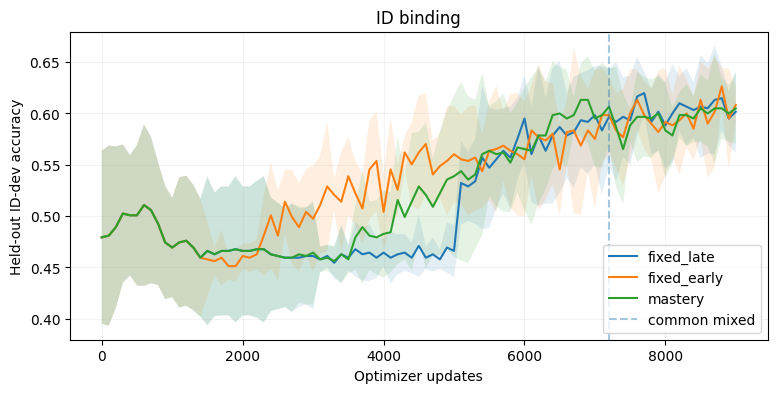

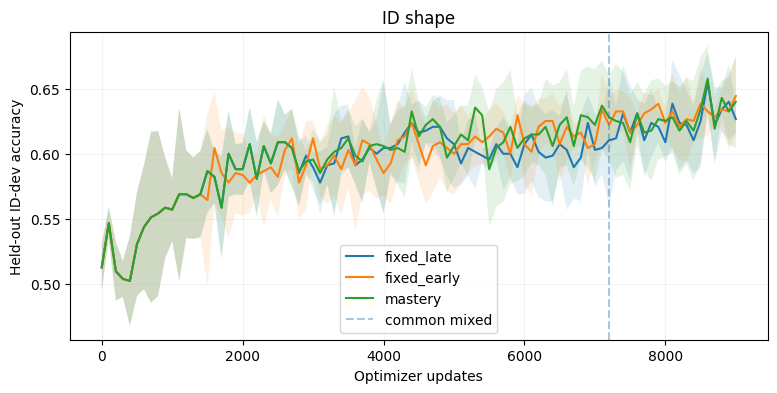

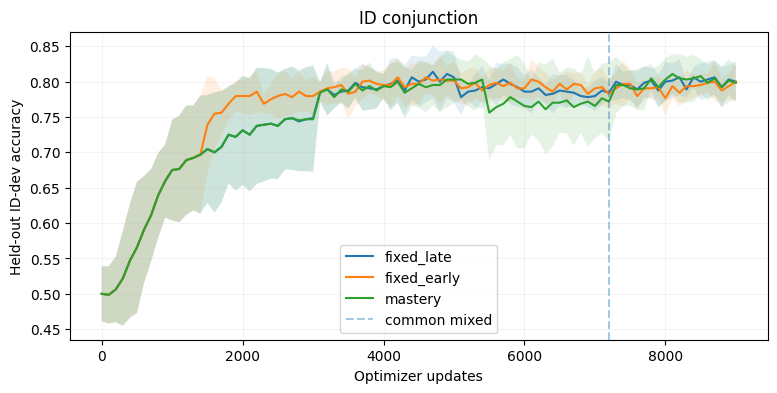

In [7]:
for task, title in (("pair", "ID binding"), ("shape", "ID shape"), ("conjunction", "ID conjunction")):
    plt.figure(figsize=(9, 4))
    for policy in POLICIES:
        curves = [{h["step"]: h["heldout_dev"]["by_template"][task] for h in r["history"]}
                  for r in report["runs"] if r["policy"] == policy and r["status"] == "completed"]
        if not curves:
            continue
        steps = sorted(set.intersection(*(set(c) for c in curves)))
        values = np.array([[curve[t] for t in steps] for curve in curves])
        mean = values.mean(0)
        sd = values.std(0, ddof=1) if len(values) > 1 else np.zeros(len(steps))
        plt.plot(steps, mean, label=policy)
        plt.fill_between(steps, mean-sd, mean+sd, alpha=0.12)
    plt.axvline(MAIN_STEPS, linestyle="--", alpha=0.4, label="common mixed")
    plt.xlabel("Optimizer updates")
    plt.ylabel("Held-out ID-dev accuracy")
    plt.title(title)
    plt.legend()
    plt.grid(alpha=0.15)
    plt.show()

**For the report:** record transition steps and reasons (`mastery`, `stage_cap`, `quota_exhausted`), per-task presentations in each phase, progress-set thresholds, and held-out performance. Rehearsal is present in all three policies, so this study **does not isolate the effect of rehearsal**. A separate rehearsal/no-rehearsal ablation can follow. Investigate plateau-triggered LR reductions and subsequent cosine decay separately rather than introducing them into these three constant-LR runs.